# Prime Video reviews – data cleaning

This notebook turns the raw Google Play reviews into three files:

| File | Content | Used for |
| --- | --- | --- |
| `prime_reviews_ratings.csv` | every review from the chosen years | star ratings |
| `prime_reviews_clean_full.csv` | every clean English review | text analysis |
| `prime_reviews_to_annotate.csv` | clean English reviews with 3 or more words | annotation |

Every step follows the same pattern: **why** the step is needed, **look** at the data, **decide and apply**, then **check** what was removed.

## 0. Setup

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import words
from fast_langdetect import detect

pd.set_option('display.max_colwidth', 120)

In [ ]:
FILE_PATH = './prime_video_reviews.csv'
APP_NAME = 'prime'
YEARS_TO_KEEP = [2022, 2023, 2026]

### Helpers
`log_step` records how many reviews are left after each step, overall and per year.
`show_removed` prints how many reviews a step removed and shows a random sample of them, so every cut can be checked by eye.

In [3]:
cleaning_log = []
year_log = []

def log_step(step_name, data):
    cleaning_log.append((step_name, len(data)))
    year_log.append(data['year'].value_counts().sort_index().rename(step_name))
    print(f"{step_name}: {len(data):,} reviews left")

def show_removed(before, after, n=10):
    removed = before[~before['reviewId'].isin(after['reviewId'])]
    print(f"Removed: {len(removed):,} reviews ({len(removed) / len(before) * 100:.1f}%)")
    if len(removed) > 0:
        return removed[['content', 'score', 'year']].sample(min(n, len(removed)), random_state=1)

## 1. First look at the raw data
**Why:** before cleaning, we need to know what the file contains: which columns, how many missing values, and which years the reviews cover.

In [4]:
df_raw = pd.read_csv(FILE_PATH)
print(df_raw.shape)
df_raw.head(3)

(847633, 11)


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,c91ebfb7-71fe-47a3-9560-a4f3ee788c1a,Arctic Wolf,https://play-lh.googleusercontent.com/a-/ALV-UjXHT0bHSI90gLpVVv3KI779N2H-aFNgeORxLpeRs90uP62blj13,"Apparently, ""Ad free"" doesn't actually mean Ad free. one star. I pay for Ad Free, that should mean Ad free, includin...",1,0,3.0.467.189247,2026-09-28 05:36:19,NaN,NaN,3.0.467.189247
1,32cef7bd-4198-4774-b53d-16f77a039bef,Jimmie Hendon,https://play-lh.googleusercontent.com/a-/ALV-UjWft-PS4B0GUWirfHZ6QJy7Q1QD8cTV-OjzVclWJdVRqB8cSHk,They charge for this on Amazon. Amazon charges you for a lot of bogus items that you shouldn't be charged for if you...,1,0,NaN,2026-09-28 05:16:23,NaN,NaN,NaN
2,c015a475-5be5-4d5d-96a7-ac5f80896cba,abhay sharma,https://play-lh.googleusercontent.com/a/ACg8ocLzDubsG-hjIWB7k86Dlulgc0GAl3Ld7oD8tkHYRHj6ThYZ4w=mo,"it has become absolutely impossible to watch anything. such long ads, and in such qty ..",1,0,3.0.471.647,2026-09-28 04:26:12,NaN,NaN,3.0.471.647


In [5]:
print(df_raw.isna().sum())

reviewId                     0
userName                     2
userImage                    0
content                     86
score                        0
thumbsUpCount                0
reviewCreatedVersion    160205
at                           0
replyContent            847633
repliedAt               847633
appVersion              160205
dtype: int64


In [6]:
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['year'] = df_raw['at'].dt.year
print("First review:", df_raw['at'].min())
print("Last review: ", df_raw['at'].max())

First review: 2015-09-25 03:46:50
Last review:  2026-09-28 07:09:40


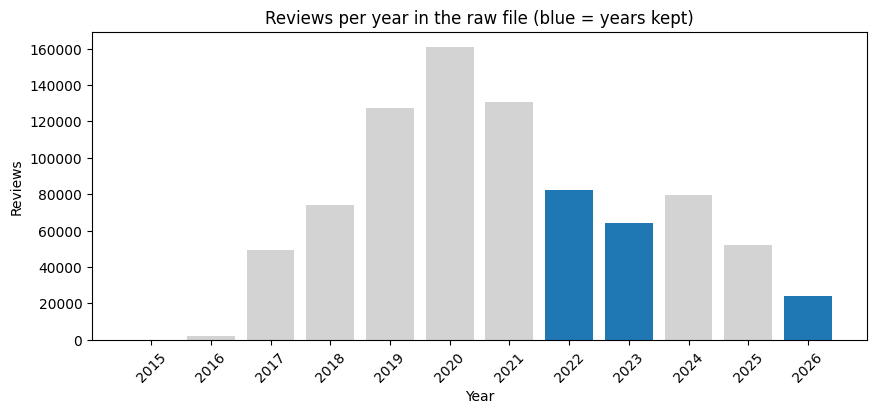

In [7]:
reviews_per_year = df_raw['year'].value_counts().sort_index()
bar_colors = ['tab:blue' if year in YEARS_TO_KEEP else 'lightgrey' for year in reviews_per_year.index]

plt.figure(figsize=(10, 4))
plt.bar(reviews_per_year.index.astype(str), reviews_per_year.values, color=bar_colors)
plt.title('Reviews per year in the raw file (blue = years kept)')
plt.xlabel('Year')
plt.ylabel('Reviews')
plt.xticks(rotation=45)
plt.show()

**What we see:** the file covers many years. The project compares a fixed set of years, so the next step keeps only those.
The last year in the file is not complete (see the last review date above), so for that year averages and shares can be compared, raw counts cannot.

## 2. Keep the project years → ratings set
**Why:** the research question compares the years set by the project. Reviews from other years are not part of the comparison.

We keep only the columns we need: the review id, text, star rating, likes and date. User names, profile pictures and app versions say nothing about consumer value, and user names are personal data we do not need.

In [8]:
df = df_raw[['reviewId', 'content', 'score', 'thumbsUpCount', 'at', 'year']].copy()
df['app'] = APP_NAME

print("Original file:", len(df_raw))
df = df[df['year'].isin(YEARS_TO_KEEP)].copy()
log_step('Years kept', df)

Original file: 847633
Years kept: 170,561 reviews left


**Decision:** the ratings set is saved here, before any text filter.
A star rating is valid whatever the review text says or which language it is written in, so star ratings are always counted on all reviews from the chosen years.

In [9]:
df_ratings = df[['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'at']].copy()
df_ratings.to_csv(f'{APP_NAME}_reviews_ratings.csv', index=False)
print("Saved ratings set:", len(df_ratings))

Saved ratings set: 170561


In [10]:
ratings_per_year = df_ratings.groupby('year')['score'].agg(['count', 'mean']).round(2)
ratings_per_year.columns = ['reviews', 'average_stars']
ratings_per_year

,reviews,average_stars
year,,
2022,82409,3.46
2023,64118,3.34
2026,24034,2.61


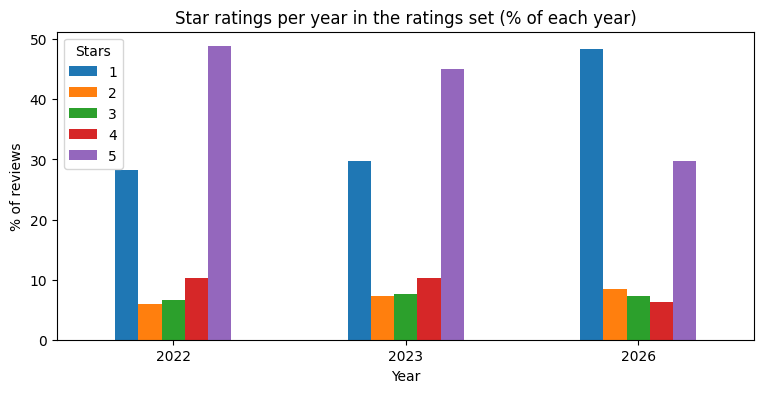

In [11]:
star_share_per_year = pd.crosstab(df_ratings['year'], df_ratings['score'], normalize='index').mul(100).round(1)
star_share_per_year.plot(kind='bar', figsize=(9, 4))
plt.title('Star ratings per year in the ratings set (% of each year)')
plt.xlabel('Year')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

## 3. Remove reviews with no text
**Why:** a review without words cannot be read or annotated. Its star rating is already kept in the ratings set.

In [12]:
print("Reviews with no text:", df['content'].isna().sum())

Reviews with no text: 16


In [13]:
df_before = df.copy()
df = df.dropna(subset=['content'])
df['content'] = df['content'].astype(str)
log_step('No missing text', df)
show_removed(df_before, df)

No missing text: 170,545 reviews left
Removed: 16 reviews (0.0%)


,content,score,year
317102,NaN,4,2023
505664,NaN,5,2022
465400,NaN,5,2023
214013,NaN,2,2022
323610,NaN,4,2022
485022,NaN,5,2023
319854,NaN,4,2023
70761,NaN,1,2023
513280,NaN,5,2022
5719,NaN,1,2026


## 4. Clean the text
**Why:** to count words and check the language, the text must be in one simple form.
We work on a copy (`content_clean`). The original `content` stays untouched, so the annotator always reads what the user really wrote.
Each sub-step below shows how many reviews it changes and some examples before and after.

### 4a. Lowercase and straight apostrophes
**Why:** "Great" and "great" should count as the same word. Phones often type curly apostrophes (’), which would make "don’t" and "don't" different words.
Apostrophes are kept, because they change the meaning ("can't" is not "can").

In [14]:
has_curly = df['content'].str.contains('[’‘]', regex=True)
print(f"Reviews with curly apostrophes: {has_curly.sum():,} ({has_curly.mean() * 100:.1f}%)")

df['content_clean'] = df['content'].str.lower()
df['content_clean'] = df['content_clean'].str.replace('’', "'").str.replace('‘', "'")

df.loc[has_curly, ['content', 'content_clean']].head(5)

Reviews with curly apostrophes: 185 (0.1%)


,content,content_clean
35,"Extremely frustrating. Whenever I try to resume a video I previously left, it just keeps loading indefinitely and ne...","extremely frustrating. whenever i try to resume a video i previously left, it just keeps loading indefinitely and ne..."
54,"There’s always a black screen bug, which makes using the app uncomfortable and kills the mood.","there's always a black screen bug, which makes using the app uncomfortable and kills the mood."
107,"Amazon Prime is honestly very disappointing. The subscription process is not clear, and the app’s support is also ve...","amazon prime is honestly very disappointing. the subscription process is not clear, and the app's support is also ve..."
235,"Very disappointed with Amazon Prime. We are already paying for a Prime subscription, yet having to watch advertiseme...","very disappointed with amazon prime. we are already paying for a prime subscription, yet having to watch advertiseme..."
266,"I’m very disappointed with this experience. Even after purchasing a one-year plan, I still have to watch ads. It fee...","i'm very disappointed with this experience. even after purchasing a one-year plan, i still have to watch ads. it fee..."


### 4b. Remove emojis, symbols and punctuation
**Why:** word counts and the dictionary check work on words only. Emojis, symbols and punctuation are replaced by a space, so words that were glued to them stay separate.
Apostrophes inside words are kept; stray quote marks around words are removed.

In [15]:
has_symbols = df['content_clean'].str.contains(r"[^a-z0-9\s']", regex=True)
print(f"Reviews with emojis, symbols or punctuation: {has_symbols.sum():,} ({has_symbols.mean() * 100:.1f}%)")

# most common characters that will be removed
removed_characters = df['content_clean'].str.findall(r"[^a-z0-9\s']").explode().dropna()
removed_characters.value_counts().head(20)

Reviews with emojis, symbols or punctuation: 91,425 (53.6%)


content_clean
.    181842
,     55556
!     25900
?     10089
👍      5212
-      5192
"      4788
/      3748
️      2927
)      2860
(      2645
😡      2343
&      2104
❤      2056
👌      1722
👎      1717
:      1539
ा      1347
*      1110
े      1100
Name: count, dtype: int64

In [16]:
df['content_clean'] = df['content_clean'].str.replace(r"[^a-z0-9\s']+", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r"(?<![a-z0-9])'+|'+(?![a-z0-9])", ' ', regex=True)

df.loc[has_symbols, ['content', 'content_clean']].sample(min(10, has_symbols.sum()), random_state=1)

,content,content_clean
101571,Uninstall!!!!!!!,uninstall
485413,❤ it ❤it❤it💯,it it it
80213,"Amazon should stop being so political . They cancel good shows that motivate the community, like Clarkson Farm. A qu...",amazon should stop being so political they cancel good shows that motivate the community like clarkson farm a qu...
504794,Great pic's 👍,great pic's
103835,The video keeps stuttering after continuously watching for around 20 mins. Only happens with Amazon prime video. I n...,the video keeps stuttering after continuously watching for around 20 mins only happens with amazon prime video i n...
254458,"Needs better shows... Also if you are watching a series and stop at a certain episode, when you go back on to contin...",needs better shows also if you are watching a series and stop at a certain episode when you go back on to continue...
466353,Streams my favorite show. The Boys.,streams my favorite show the boys
514146,Excellent 😁,excellent
468100,"The Prime Video App works well, online and offline. There seems to be an expiration time for downloads though, but w...",the prime video app works well online and offline there seems to be an expiration time for downloads though but w...
75179,"Kept crashing,, could not sign in",kept crashing could not sign in


### 4c. Remove words that contain numbers
**Why:** tokens like "4k", "v2" or "2023" are versions, prices or dates, not words. If kept, they would make a review look longer, and less English, than it is.

In [17]:
number_tokens = df['content_clean'].str.findall(r"\S*\d\S*").explode().dropna()
has_numbers = df['content_clean'].str.contains(r"\d", regex=True)
print(f"Reviews with a number token: {has_numbers.sum():,} ({has_numbers.mean() * 100:.1f}%)")
print("Most common number tokens:")
number_tokens.value_counts().head(20)

Reviews with a number token: 16,176 (9.5%)
Most common number tokens:


content_clean
1       2723
2       2428
5       2279
3       1788
10      1255
4       1133
30       684
6        458
7        448
0        446
20       443
4k       349
8        340
1499     334
99       330
15       321
100      315
1500     269
9        267
2022     221
Name: count, dtype: int64

In [18]:
df['content_clean'] = df['content_clean'].str.replace(r"\S*\d\S*", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

df.loc[has_numbers, ['content', 'content_clean']].sample(min(10, has_numbers.sum()), random_state=1)

,content,content_clean
105265,Included with Prime now has movies with Starz 30 day free trial?!! No idiot that isn't included with Prime if I need...,included with prime now has movies with starz day free trial no idiot that isn't included with prime if i need to si...
9153,"Honestly I wish I could give it 0 stars. This app is the definition of greedy, everything I want to watch I have to ...",honestly i wish i could give it stars this app is the definition of greedy everything i want to watch i have to pay ...
258118,Undoubtedly! Amazon Prime is great OTT platform but I miss one of the feature of speed. I watched all the show on 2x...,undoubtedly amazon prime is great ott platform but i miss one of the feature of speed i watched all the show on but ...
255127,90% of the app is buy or rent. That is why I will be getting rid of it,of the app is buy or rent that is why i will be getting rid of it
6287,I am subscriber of Amazon Prime but they show add every 10 mint I don't pay for add,i am subscriber of amazon prime but they show add every mint i don't pay for add
94239,Moti g70 tab has wide1 L1 support but prime not detecting it,moti tab has support but prime not detecting it
102561,I can't use gcash trial for 7 days.,i can't use gcash trial for days
83716,Worst experience...every time show blank sceen and freeze after 1 hour of use ...price almost equal to Netflix but a...,worst experience every time show blank sceen and freeze after hour of use price almost equal to netflix but app stan...
70028,"The image quality is like 240p no matter what network we use, whether it's WiFi or a data package, the image is very...",the image quality is like no matter what network we use whether it's wifi or a data package the image is very bad
509689,"I but, DC tv show DC's legends of tomorrow season 7, the flash season 8 episode 12 and episode 13 come soon to pleas...",i but dc tv show dc's legends of tomorrow season the flash season episode and episode come soon to please company pr...


### 4d. Remove reviews with no real word left
**Why:** after cleaning, some reviews are empty or only single letters (they were only emojis, numbers or symbols). They have nothing to read or annotate.
A review must contain at least one word of two or more letters.

In [19]:
df_before = df.copy()
df = df[df['content_clean'].str.contains(r'[a-z]{2,}', regex=True)].copy()
log_step('Has a real word', df)
show_removed(df_before, df)

Has a real word: 167,443 reviews left
Removed: 3,102 reviews (1.8%)


,content,score,year
302586,ಸೂಪರ್,4,2026
460066,😊😊😊,5,2023
497543,👍,5,2022
517966,😘😘😘😘😘,5,2022
69204,💯🤮,1,2023
492378,❤️❤️❤️,5,2022
467807,👍👍👍👍👍,5,2023
321941,👍,4,2022
91325,पूरा 2GB का वीडियो डाउनलोड करने के बाद हिंदी ऑडियो नही चला और ना ही हिंदी ऑडियो का ऑप्शन दिया ।,1,2022
409806,❤️,5,2026


## 5. Keep English reviews
**Why:** the annotation and the word checks are in English. Two checks are used:
- **5a. Language detector:** removes reviews written in another language.
- **5b. Dictionary check:** removes gibberish and other-language text the detector missed.

### 5a. Language detector
The language is detected on the **original** text, because punctuation and full sentences help the detector.

In [20]:
def detect_language(text):
    try:
        result = detect(text.replace('\n', ' '), model='auto', k=1)
        return result[0]['lang']
    except Exception:
        return 'unknown'

df['language'] = df['content'].apply(detect_language)
language_counts = df['language'].value_counts()
print(f"Detected as English: {(df['language'] == 'en').sum():,} ({(df['language'] == 'en').mean() * 100:.1f}%)")
language_counts.head(15)

Detected as English: 158,388 (94.6%)


language
en     158388
it       1301
es        948
de        903
fr        795
pt        569
id        565
nl        531
sv        245
ru        232
hu        223
ja        223
ceb       175
pl        160
fi        142
Name: count, dtype: int64

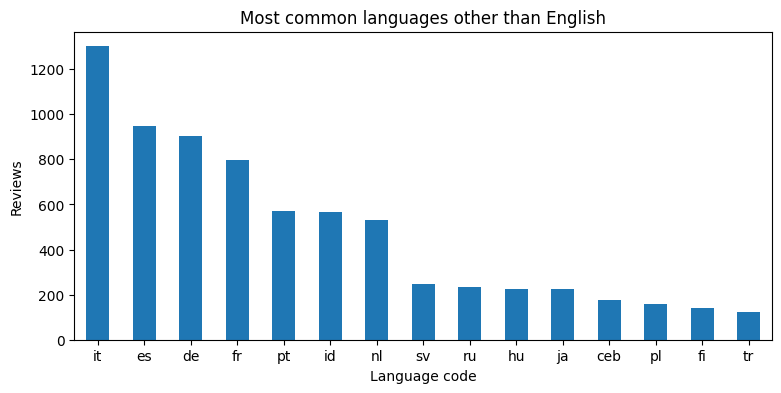

In [21]:
plt.figure(figsize=(9, 4))
language_counts.drop('en', errors='ignore').head(15).plot(kind='bar')
plt.title('Most common languages other than English')
plt.xlabel('Language code')
plt.ylabel('Reviews')
plt.xticks(rotation=0)
plt.show()

In [22]:
# examples of reviews detected as another language
not_english = df[df['language'] != 'en']
not_english[['content', 'language']].sample(min(15, len(not_english)), random_state=1)

,content,language
471145,Mm oo m oo. N,azb
527030,My go to!,io
253640,Ok,it
68254,Panget ito,tl
471311,Vedapubda punda,it
321482,Hay películas que dicen que están en la plataforma y al buscarlas no aparecen o aparece el auto completar pero no sa...,es
11000,useless,vi
474791,Fun.,de
80424,Bakvas,lt
71507,"Subtitle gak sesuai sama audio, gak match Subtitle nya terlalu cepet",id


In [23]:
not_english

,reviewId,content,score,thumbsUpCount,at,year,app,content_clean,language
4,43c97ff4-a65a-488d-9f99-0e3e66afb698,"La aplicación tiene muchas fallas en cuestión de pagar la suscripción e iniciar sesión, te bloquea la cuenta",1,1,2026-09-28 02:58:07,2026,prime,la aplicaci n tiene muchas fallas en cuesti n de pagar la suscripci n e iniciar sesi n te bloquea la cuenta,es
48,a8d6ae11-699b-4f94-9759-701e9a94742d,HAEJCL,1,1,2026-09-27 07:41:34,2026,prime,haejcl,it
56,2026c1db-8a04-4b33-9eeb-d4b25a8465cc,"o sistema de pagamento de vcs não é confiável, já tive cobranças sem meu consentimento e quando deixo. a tv as pesso...",1,1,2026-09-27 03:18:17,2026,prime,o sistema de pagamento de vcs n o confi vel j tive cobran as sem meu consentimento e quando deixo a tv as pessoas co...,pt
122,eb450739-a490-4796-8cec-ddf19bb463ca,"Difícil cancelar suscripción, atracadores",1,0,2026-09-25 23:17:38,2026,prime,dif cil cancelar suscripci n atracadores,es
167,645ae30f-ac8d-41c2-aeb0-16579cad8ee5,"¿Por qué tendrías que estar pagando el triple para tener un prime ""normal""? como por ejemplo Disney o Netflix. Ademá...",1,0,2026-09-24 23:58:53,2026,prime,por qu tendr as que estar pagando el triple para tener un prime normal como por ejemplo disney o netflix adem s de p...,es
...,...,...,...,...,...,...,...,...,...
527990,19e1e955-b0ed-452f-be4b-dc4cea0c6cbc,Great👍👍👍👍,5,0,2022-01-01 16:36:19,2022,prime,great,pt
528010,1ed31944-8798-47bc-a29f-31a9b07923e7,Nice 👍,5,0,2022-01-01 14:30:49,2022,prime,nice,fr
528050,bbff2925-a085-4da3-b780-c19ad62ffb1d,Nice!,5,0,2022-01-01 09:32:37,2022,prime,nice,it
528071,80d94bce-79c2-408a-a5bc-d4ea7c391970,Nice app...,5,0,2022-01-01 06:13:13,2022,prime,nice app,fr


In [24]:
not_english_words = not_english['content_clean'].str.split().str.len()
not_english_short = not_english[not_english_words < 3]

print(f"Non-English reviews with fewer than 3 words: {len(not_english_short):,} of {len(not_english):,}")
not_english_short[['content', 'content_clean', 'language']]

Non-English reviews with fewer than 3 words: 5,893 of 9,055


,content,content_clean,language
48,HAEJCL,haejcl,it
499,glitch af,glitch af,da
510,bakvash,bakvash,tr
653,traitors!,traitors,de
731,dirka,dirka,sl
...,...,...,...
527990,Great👍👍👍👍,great,pt
528010,Nice 👍,nice,fr
528050,Nice!,nice,it
528071,Nice app...,nice app,fr


In [25]:
not_english_long = not_english[not_english_words >= 3]

print(f"Non-English reviews with 3 or more words: {len(not_english_long):,} of {len(not_english):,}")
not_english_long[['content', 'content_clean', 'language']]

Non-English reviews with 3 or more words: 3,162 of 9,055


,content,content_clean,language
4,"La aplicación tiene muchas fallas en cuestión de pagar la suscripción e iniciar sesión, te bloquea la cuenta",la aplicaci n tiene muchas fallas en cuesti n de pagar la suscripci n e iniciar sesi n te bloquea la cuenta,es
56,"o sistema de pagamento de vcs não é confiável, já tive cobranças sem meu consentimento e quando deixo. a tv as pesso...",o sistema de pagamento de vcs n o confi vel j tive cobran as sem meu consentimento e quando deixo a tv as pessoas co...,pt
122,"Difícil cancelar suscripción, atracadores",dif cil cancelar suscripci n atracadores,es
167,"¿Por qué tendrías que estar pagando el triple para tener un prime ""normal""? como por ejemplo Disney o Netflix. Ademá...",por qu tendr as que estar pagando el triple para tener un prime normal como por ejemplo disney o netflix adem s de p...,es
175,loading doang lama ngga masuk masuk,loading doang lama ngga masuk masuk,ms
...,...,...,...
527501,I líke it,i l ke it,is
527792,No I do no no no,no i do no no no,pt
527866,Ek no 1 app,ek no app,af
527934,THE B E S T,the b e s t,it


In [26]:
df_before = df.copy()
df = df[df['language'] == 'en'].copy()
log_step('English (detector)', df)
show_removed(df_before, df)

English (detector): 158,388 reviews left
Removed: 9,055 reviews (5.4%)


,content,score,year
471145,Mm oo m oo. N,5,2023
527030,My go to!,5,2022
253640,Ok,3,2023
68254,Panget ito,1,2023
471311,Vedapubda punda,5,2023
321482,Hay películas que dicen que están en la plataforma y al buscarlas no aparecen o aparece el auto completar pero no sa...,4,2022
11000,useless,1,2026
474791,Fun.,5,2023
80424,Bakvas,1,2023
71507,"Subtitle gak sesuai sama audio, gak match Subtitle nya terlalu cepet",1,2023


### 5b. Dictionary check
**Why:** some reviews pass the detector but are not readable English: gibberish ("eww ee ww"), names, or other languages written in Latin letters.
For each review we compute the share of its words that are English words. A review is kept if at least `MIN_REAL_WORD_RATIO` of its words are real words.

**A strict dictionary is not enough.** The NLTK word list misses many normal forms ("crashing", "discontinued") and app words ("netflix", "subscription"). So a word also counts as real if:
- it contains an apostrophe (contractions like "don't", "it's");
- it is an app or streaming word from our list;
- it is a dictionary word plus a common ending (-s, -es, -d, -ed, -ing, -ly, -er), also with a doubled letter ("stopped" → "stop").

In [27]:
nltk.download('words', quiet=True)
english_vocab = set(w.lower() for w in words.words())
app_words = {'netflix', 'amazon', 'prime', 'app', 'apps', 'tv','ads',  'adverts', 'advt',
             'subscription', 'subscriptions', 'streaming', 'login', 'logout', 'wifi',
             'chromecast', 'android', 'iphone', 'ipad', 'hd', 'overpriced', 'cancelled', 'canceled'}
english_vocab = english_vocab | app_words

def is_dictionary_word(word):
    return word in english_vocab

def is_real_word(word):
    if "'" in word or word in english_vocab:
        return True
    for ending in ['s', 'es', 'd', 'ed', 'ing', 'ly', 'er']:
        if word.endswith(ending):
            base = word[:-len(ending)]
            if len(base) >= 3 and (base in english_vocab or base[:-1] in english_vocab):
                return True
    return False

def real_word_ratio(text, word_check):
    tokens = text.split()
    return sum(1 for w in tokens if word_check(w)) / len(tokens)

df['strict_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_dictionary_word))
df['real_word_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_real_word))
df['real_word_ratio'].describe()

count    158388.000000
mean          0.950096
std           0.137490
min           0.000000
25%           0.960000
50%           1.000000
75%           1.000000
max           1.000000
Name: real_word_ratio, dtype: float64

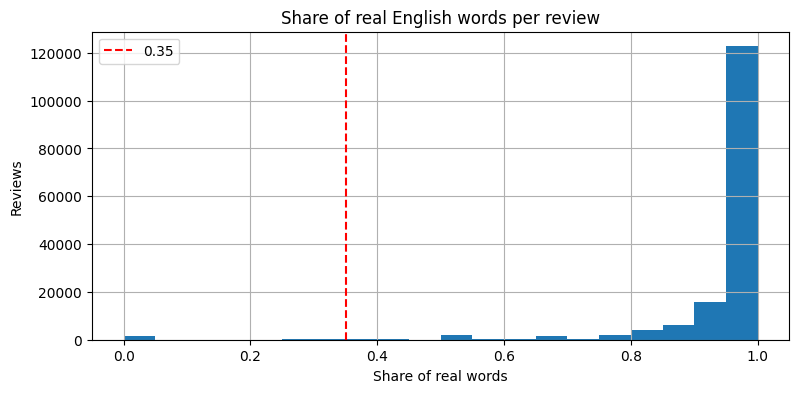

In [28]:
plt.figure(figsize=(9, 4))
df['real_word_ratio'].hist(bins=20)
plt.axvline(0.35, color='red', linestyle='--', label='0.35')
plt.title('Share of real English words per review')
plt.xlabel('Share of real words')
plt.ylabel('Reviews')
plt.legend()
plt.show()

**Choosing the threshold:** compare how many reviews each threshold removes, and read examples in each band.

In [29]:
for threshold in [0.25, 0.35, 0.5]:
    removed = (df['real_word_ratio'] < threshold).sum()
    print(f"Threshold {threshold}: removes {removed:,} reviews ({removed / len(df) * 100:.1f}%)")

Threshold 0.25: removes 1,797 reviews (1.1%)
Threshold 0.35: removes 2,189 reviews (1.4%)
Threshold 0.5: removes 2,594 reviews (1.6%)


In [30]:
bands = [(0, 0.25), (0.25, 0.35), (0.35, 0.5)]
for low, high in bands:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    print(f"--- share of real words {low}–{high}: {len(band):,} reviews ---")
    print(band['content'].sample(min(10, len(band)), random_state=1).to_string(index=False))
    print()

--- share of real words 0–0.25: 1,797 reviews ---
 Bhuat aachi ablicakison hai
      Raju kondappa baspuram
                       Hnice
                        Owsm
                        Thik
                    Greatest
                    Robotic,
        # wzz😙😁😺😳😏😎😎🙏😦🙏😦😦🌎🗼⛲
                      Bakwas
Hhhh🍨3g😅🍦☀️🍨😅🍨🍨🍨🍦🍨🍨🍨🍨🍨🍨🍦😅🍦☀️

--- share of real words 0.25–0.35: 392 reviews ---
                                                 download film/series lama banget ajg nyesel gw langganan
                                                                                             G tere ki gf
                                                          yv2naw momllll look lol lol llllll llll l ml of
                                                                                     Sabse kharab service
                                                                         Suno na kya 6jh bhi duj jhjhh to
                                                                          movi

**Strict vs loosened dictionary:** these reviews would be removed with the strict word list but are kept with the loosened one.

In [31]:
brought_back = df[(df['strict_ratio'] < 0.35) & (df['real_word_ratio'] >= 0.35)]
print("Reviews kept thanks to the loosened dictionary:", len(brought_back))
brought_back[['content', 'content_clean']].sample(min(15, len(brought_back)), random_state=1)

Reviews kept thanks to the loosened dictionary: 908


,content,content_clean
475211,It's deserve 5 Stars,it's deserve stars
88697,Sucks.,sucks
518178,Supers,supers
75825,Vedio not playing,vedio not playing
465304,"Reacher, Clancy, it's addictive.",reacher clancy it's addictive
97402,Vedio not playing,vedio not playing
89874,Spammed push notifications,spammed push notifications
257381,Update movies plz.,update movies plz
494899,Impressed,impressed
462867,It's expensive appa,it's expensive appa


In [32]:
MIN_REAL_WORD_RATIO = 0.35

df_before = df.copy()
df = df[df['real_word_ratio'] >= MIN_REAL_WORD_RATIO].copy()
df = df.drop(columns=['strict_ratio', 'real_word_ratio', 'language'])
log_step('Real English words', df)
show_removed(df_before, df, n=20)

Real English words: 156,199 reviews left
Removed: 2,189 reviews (1.4%)


,content,score,year
91869,Higgg,1,2022
315499,Pj @,4,2023
98077,Glitches,1,2022
510380,Mirzapur 🔥🔥,5,2022
476667,Owsome,5,2023
71944,Sivaiah Naidu,1,2023
207839,"...0ppl ,lm.ki",2,2023
322442,"qa44krdok kL,🙉🤎 46 rZaa lll rkalkth4 j4,$$%% ,vhke nR•",4,2022
521308,Pra,5,2022
508897,Superhit superhit superhit respect from Varanasi,5,2022


## 6. Save the full clean set
This set keeps every clean English review. It is used for the text analysis, so it is not reduced any further.

In [33]:
df['word_count'] = df['content_clean'].str.split().str.len()
df_clean_full = df.copy()
df_clean_full.to_csv(f'{APP_NAME}_reviews_clean_full.csv', index=False)
print("Saved full clean set:", len(df_clean_full))

Saved full clean set: 156199


**Check: does the text cleaning change the star ratings?** If the averages per year are close, removing empty, non-English and gibberish reviews does not bias the ratings.

In [34]:
rating_check = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean()}).round(2)
rating_check['difference'] = rating_check['clean_text_set'] - rating_check['ratings_set']
rating_check

,ratings_set,clean_text_set,difference
year,,,
2022,3.46,3.42,-0.04
2023,3.34,3.32,-0.02
2026,2.61,2.57,-0.04


## 7. Review length → annotation set
**Why:** the annotation looks for the *reasons* behind satisfaction (price, ads, content, technical problems). The star rating already tells us *how* satisfied a user is.
Very short reviews ("good", "love it") show a feeling but rarely a reason. We look at the data to decide how many words a review needs.

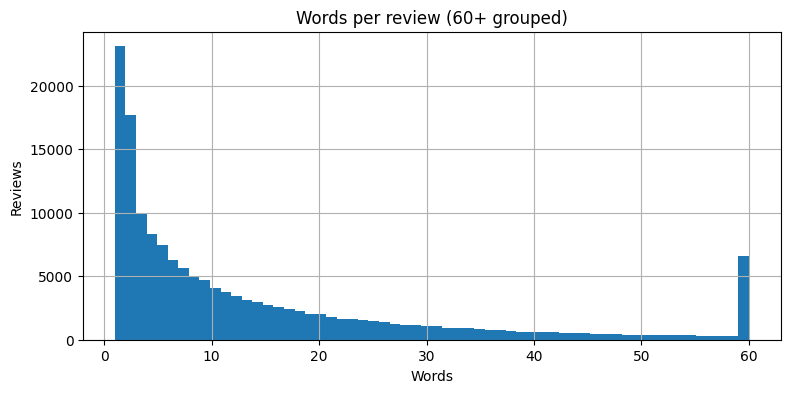

In [35]:
plt.figure(figsize=(9, 4))
df_clean_full['word_count'].clip(upper=60).hist(bins=60)
plt.title('Words per review (60+ grouped)')
plt.xlabel('Words')
plt.ylabel('Reviews')
plt.show()

In [36]:
df_clean_full['words_group'] = df_clean_full['word_count'].clip(upper=11)
group_labels = {i: str(i) for i in range(1, 11)}
group_labels[11] = '11+'

length_table = df_clean_full.groupby('words_group').agg(
    reviews=('reviewId', 'count'),
    average_stars=('score', 'mean'))
length_table['% of reviews'] = (length_table['reviews'] / len(df_clean_full) * 100).round(1)
length_table['average_stars'] = length_table['average_stars'].round(2)
length_table.index = length_table.index.map(group_labels)
length_table

,reviews,average_stars,% of reviews
words_group,,,
1,23091,4.60,14.8
2,17664,4.24,11.3
3,10009,3.74,6.4
4,8356,3.66,5.3
5,7421,3.50,4.8
6,6245,3.37,4.0
7,5615,3.29,3.6
8,5018,3.16,3.2
9,4678,3.04,3.0


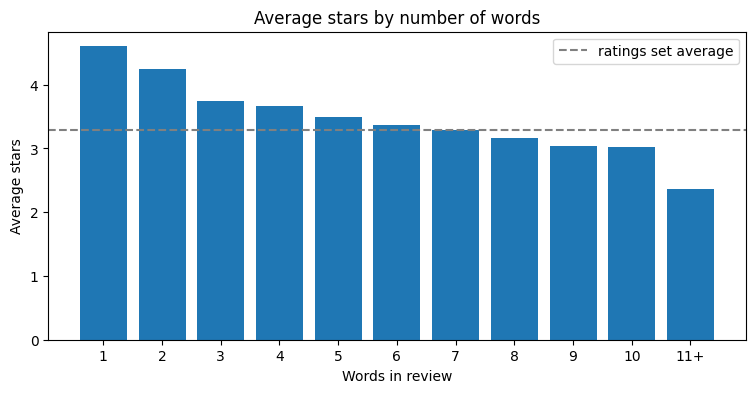

In [37]:
plt.figure(figsize=(9, 4))
plt.bar(length_table.index, length_table['average_stars'])
plt.axhline(df_ratings['score'].mean(), color='grey', linestyle='--', label='ratings set average')
plt.title('Average stars by number of words')
plt.xlabel('Words in review')
plt.ylabel('Average stars')
plt.legend()
plt.show()

**Do short reviews talk about value?** We count reviews that mention a price, ads or subscription word, by length.

In [38]:
value_words = (r"\b(price|prices|expensive|cheap|money|cost|costs|pay|paid|paying|worth|subscription|"
               r"rent|rental|ads|ad|advt|advertisement|advertisements|free|fee|charge|charged|membership)\b")
df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)

value_table = df_clean_full.groupby('words_group')['mentions_value'].agg(['mean', 'sum'])
value_table.columns = ['% mentioning value', 'reviews mentioning value']
value_table['% mentioning value'] = (value_table['% mentioning value'] * 100).round(1)
value_table.index = value_table.index.map(group_labels)
value_table

C:\Users\elesa\AppData\Local\Temp\ipykernel_17420\2328727743.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)


,% mentioning value,reviews mentioning value
words_group,,
1,0.4,91
2,1.2,211
3,6.0,599
4,5.7,476
5,7.7,571
6,9.8,611
7,11.7,658
8,13.2,662
9,15.4,722


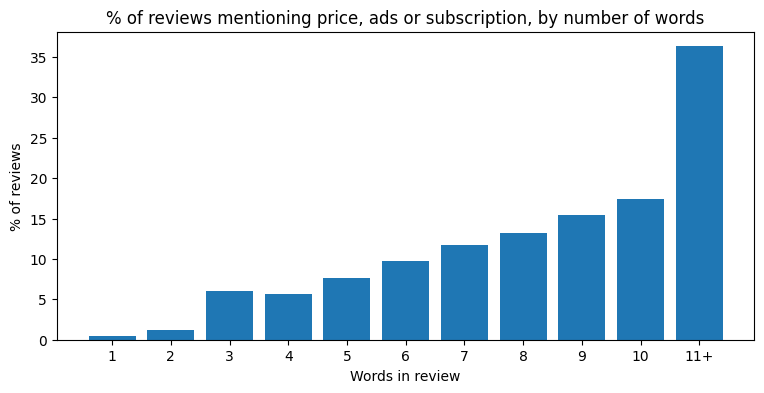

In [39]:
plt.figure(figsize=(9, 4))
plt.bar(value_table.index, value_table['% mentioning value'])
plt.title('% of reviews mentioning price, ads or subscription, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% of reviews')
plt.show()

**Reading examples:** do reviews of this length give a reason?

In [40]:
for n_words in [1, 2, 3, 4, 5]:
    print(f"--- {n_words} words ---")
    same_length = df_clean_full[df_clean_full['word_count'] == n_words]['content']
    examples = same_length.sample(min(15, len(same_length)), random_state=1)
    print(examples.to_string(index=False))
    print()

--- 1 words ---
     Nice
      Gay
Excellent
     Nice
  Awesome
     Good
  Average
     Good
   Superb
     Good
     Good
 Good 👍👍😊
     Good
     good
     Good

--- 2 words ---
     love it.
    Very nice
     The best
   Good value
    Worst app
 Works great!
      Love it
Excellent App
 Overall good
no complaints
     the best
    not bad 👌
     Good app
 Great videos
Limited shows

--- 3 words ---
           too many ads
        Very good app 👌
          Very nice app
     Great video app!!!
  So much entertainment
  Enjoy your selection.
    Showing fake movies
       It's not opening
     Absolutely Love it
          Best app ever
   Very good experience
          This is great
   Very good experience
Best perchance ever ❤️.
   Amazon prime video 😁

--- 4 words ---
           I love this App
  Picture quality not good
       Great app and shows
 Better best and completed
   Stupid app Super stupid
Always trusted Prime Video
   Pretty easy to navigate
     Not a great selecti

**Comparing cuts:** what each minimum length keeps, and how it changes the stars and the years.

In [41]:
cut_rows = []
for min_words in [1, 2, 3, 4, 5]:
    kept = df_clean_full[df_clean_full['word_count'] >= min_words]
    row = {'minimum words': min_words,
           'reviews kept': len(kept),
           '% kept': round(len(kept) / len(df_clean_full) * 100, 1),
           'average stars': round(kept['score'].mean(), 2),
           '% 5 stars': round((kept['score'] == 5).mean() * 100, 1)}
    for year in YEARS_TO_KEEP:
        year_total = (df_clean_full['year'] == year).sum()
        row[f'% of {year} kept'] = round((kept['year'] == year).sum() / year_total * 100, 1)
    cut_rows.append(row)

cut_table = pd.DataFrame(cut_rows)
cut_table

,minimum words,reviews kept,% kept,average stars,% 5 stars,% of 2022 kept,% of 2023 kept,% of 2026 kept
0,1,156199,100.0,3.26,43.8,100.0,100.0,100.0
1,2,133108,85.2,3.03,37.7,82.7,87.2,88.4
2,3,115444,73.9,2.84,32.4,70.4,75.9,80.2
3,4,105435,67.5,2.75,29.9,63.8,69.6,74.2
4,5,97079,62.2,2.68,27.7,58.4,64.1,69.5


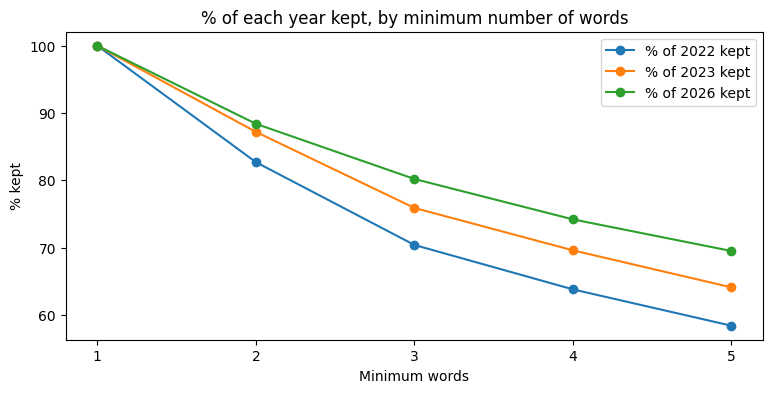

In [42]:
year_columns = [f'% of {year} kept' for year in YEARS_TO_KEEP]
cut_table.set_index('minimum words')[year_columns].plot(marker='o', figsize=(9, 4))
plt.title('% of each year kept, by minimum number of words')
plt.xlabel('Minimum words')
plt.ylabel('% kept')
plt.xticks(cut_table['minimum words'])
plt.show()

**Decision: 3 words or more.**
- 1–2 word reviews are almost only general praise and rarely give a reason.
- From 3 words, reviews start to give reasons, including short value complaints ("too many ads"). A 4-word minimum would lose these.
- Any minimum length makes the set more negative and more recent, because longer reviews are more often complaints and recent reviews are longer. This cannot be avoided if we want reasons, which is why star ratings are always taken from the ratings set.

In [43]:
MIN_WORDS = 3

df_before = df_clean_full.copy()
df_annotate = df_clean_full[df_clean_full['word_count'] >= MIN_WORDS].copy()
log_step(f'{MIN_WORDS}+ words', df_annotate)
show_removed(df_before, df_annotate, n=20)

3+ words: 115,444 reviews left
Removed: 40,755 reviews (26.1%)


,content,score,year
521263,Excellent,5,2022
495073,Wonderful App,5,2022
85736,Extra amazingh,1,2022
475169,Nice,5,2023
524166,Good,5,2022
481834,Awesome app,5,2023
462578,Awesome 😎👍,5,2023
503767,Best,5,2022
517772,Really nice...,5,2022
461902,Good,5,2023


## 8. Why likes are not used to select reviews
**Why check:** likes could be a signal that a review is useful. Here we test whether a likes rule would improve the selection. Nothing is removed in this section.

In [44]:
has_like = df_clean_full['thumbsUpCount'] >= 1
like_table = pd.crosstab(df_clean_full['year'], df_clean_full['score'], values=has_like, aggfunc='mean').mul(100).round(1)
like_table

score,1,2,3,4,5
year,,,,,
2022,22.9,26.5,20.1,11.8,5.5
2023,26.2,34.7,27.3,17.1,8.2
2026,48.9,50.4,39.6,32.5,18.0


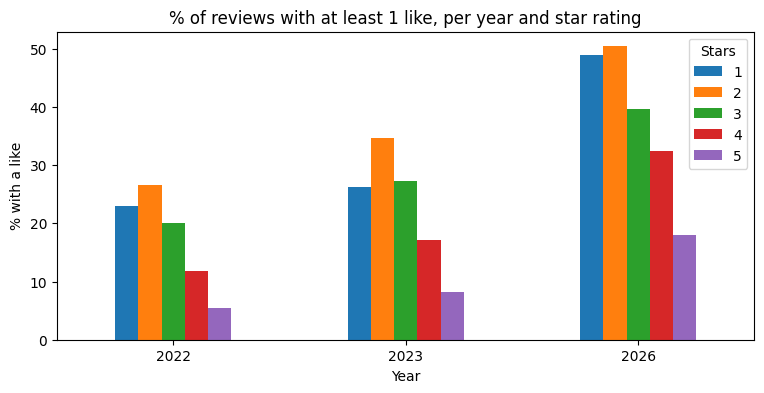

In [45]:
like_table.plot(kind='bar', figsize=(9, 4))
plt.title('% of reviews with at least 1 like, per year and star rating')
plt.xlabel('Year')
plt.ylabel('% with a like')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

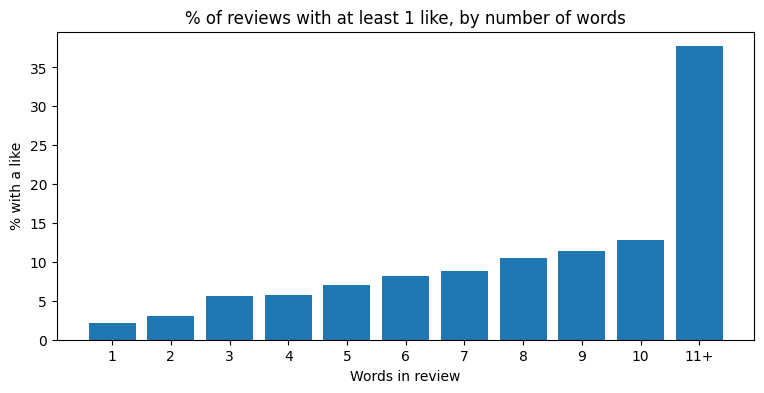

In [46]:
like_by_length = has_like.groupby(df_clean_full['words_group']).mean().mul(100).round(1)
like_by_length.index = like_by_length.index.map(group_labels)

plt.figure(figsize=(9, 4))
plt.bar(like_by_length.index, like_by_length.values)
plt.title('% of reviews with at least 1 like, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% with a like')
plt.show()

**Testing a likes rule:** keep a review if it has enough words **or** enough likes. Long reviews already pass the words test, so the likes can only add short reviews.

In [47]:
like_rows = []
words_mask = df_clean_full['word_count'] >= MIN_WORDS
for min_likes in [1, 2, 5, 10]:
    likes_mask = df_clean_full['thumbsUpCount'] >= min_likes
    kept = df_clean_full[words_mask | likes_mask]
    like_rows.append({'rule': f'{MIN_WORDS}+ words or {min_likes}+ likes',
                      'reviews kept': len(kept),
                      'short reviews added by likes': (~words_mask & likes_mask).sum(),
                      'average stars': round(kept['score'].mean(), 2)})
for min_likes in [1, 5]:
    kept = df_clean_full[df_clean_full['thumbsUpCount'] >= min_likes]
    like_rows.append({'rule': f'{min_likes}+ likes only',
                      'reviews kept': len(kept),
                      'short reviews added by likes': None,
                      'average stars': round(kept['score'].mean(), 2)})

print(f"{MIN_WORDS}+ words alone: {words_mask.sum():,} reviews, average stars {df_annotate['score'].mean():.2f}")
pd.DataFrame(like_rows)

3+ words alone: 115,444 reviews, average stars 2.84


,rule,reviews kept,short reviews added by likes,average stars
0,3+ words or 1+ likes,116463,1019.0,2.85
1,3+ words or 2+ likes,115504,60.0,2.84
2,3+ words or 5+ likes,115460,16.0,2.84
3,3+ words or 10+ likes,115454,10.0,2.84
4,1+ likes only,29328,NaN,2.29
5,5+ likes only,6130,NaN,2.35


**Decision: no likes rule.**
- Adding likes rescues only a few short reviews and barely changes the selection.
- Likes go more often to negative reviews and depend on the year, so they are not a neutral signal of a useful review.
- Selecting on likes alone keeps few reviews and is strongly skewed.

## 9. Repeated texts
**Why check:** many identical reviews could be spam or a coordinated campaign rather than individual opinions.
Common short phrases ("i love this app") repeat naturally. A campaign looks like one specific message, often off-topic, many times, with all 1 or all 5 stars.

**Decision:** repeated texts are kept, because they are real reviews. The column `text_repeats` (how many times the same clean text appears) is added, so they can be identified or excluded later in the analysis.

In [48]:
df_annotate['text_repeats'] = df_annotate.groupby('content_clean')['reviewId'].transform('count')

repeated = (df_annotate[df_annotate['text_repeats'] >= 5]
            .groupby('content_clean')
            .agg(times=('reviewId', 'count'), average_stars=('score', 'mean'),
                 first_year=('year', 'min'), last_year=('year', 'max'))
            .sort_values('times', ascending=False))
repeated['average_stars'] = repeated['average_stars'].round(2)
print("Texts repeated 5 or more times:", len(repeated))
print("Reviews involved:", repeated['times'].sum())
repeated.head(25)

Texts repeated 5 or more times: 347
Reviews involved: 5099


,times,average_stars,first_year,last_year
content_clean,,,,
i love it,323,4.94,2022,2026
love this app,267,4.97,2022,2026
very good app,252,4.73,2022,2026
easy to use,220,4.89,2022,2026
very nice app,153,4.86,2022,2026
i love this app,145,4.97,2022,2026
i like it,138,4.81,2022,2026
too many ads,134,1.57,2022,2026
very bad app,88,1.08,2022,2026


## 10. Save the annotation set

In [51]:
df_annotate_unique = df_annotate.drop_duplicates(subset=['content_clean']).copy()
log_step('Dataset without duplicates', df_annotate_unique)
show_removed(df_annotate, df_annotate_unique)

annotate_cols = ['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'word_count', 'text_repeats', 'content', 'content_clean']
df_annotate_unique[annotate_cols].to_csv(f'{APP_NAME}_reviews_to_annotate.csv', index=False)

Dataset without duplicates: 108,815 reviews left
Removed: 6,629 reviews (5.7%)


! Remeber to eventually redistribute the labels back to every review

## 11. Summary
### Reviews left after each step

In [52]:
log = pd.DataFrame(cleaning_log, columns=['step', 'rows_left'])
log['removed'] = log['rows_left'].shift(1) - log['rows_left']
log['removed_%_of_previous'] = (log['removed'] / log['rows_left'].shift(1) * 100).round(1)
print("Original file:", len(df_raw))
print(log.to_string(index=False))

Original file: 847633
                      step  rows_left  removed  removed_%_of_previous
                Years kept     170561      NaN                    NaN
           No missing text     170545     16.0                    0.0
           Has a real word     167443   3102.0                    1.8
        English (detector)     158388   9055.0                    5.4
        Real English words     156199   2189.0                    1.4
                  3+ words     115444  40755.0                   26.1
Dataset without duplicates     108815   6629.0                    5.7


In [53]:
year_table = pd.concat(year_log, axis=1)
year_table

,Years kept,No missing text,Has a real word,English (detector),Real English words,3+ words,Dataset without duplicates
year,,,,,,,
2022,82409,82402,80781,76171,74939,52790,49049
2023,64118,64110,62944,59410,58583,44471,42242
2026,24034,24033,23718,22807,22677,18183,17524


In [54]:
# % of each year's reviews still left after each step
year_pct = (year_table.div(year_table['Years kept'], axis=0) * 100).round(1)
year_pct

,Years kept,No missing text,Has a real word,English (detector),Real English words,3+ words,Dataset without duplicates
year,,,,,,,
2022,100.0,100.0,98.0,92.4,90.9,64.1,59.5
2023,100.0,100.0,98.2,92.7,91.4,69.4,65.9
2026,100.0,100.0,98.7,94.9,94.4,75.7,72.9


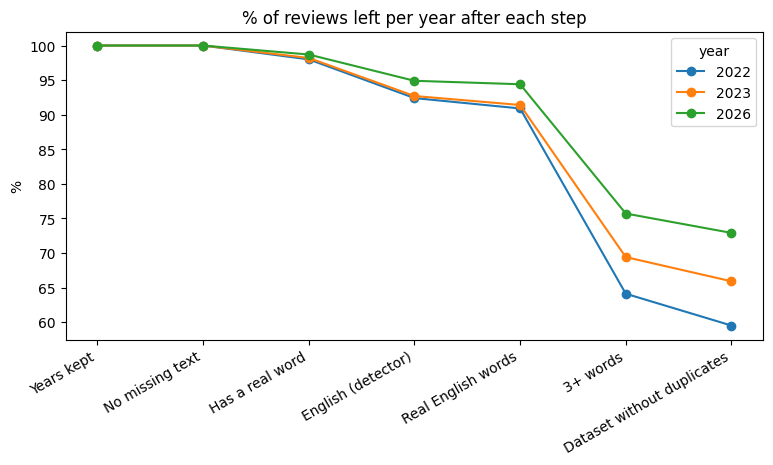

In [55]:
year_pct.T.plot(marker='o', figsize=(9, 4))
plt.title('% of reviews left per year after each step')
plt.ylabel('%')
plt.xticks(range(len(year_pct.columns)), year_pct.columns, rotation=30, ha='right')
plt.show()

### Star ratings in the three sets
The ratings set and the clean text set should be close. The annotation set is expected to be more negative, because it keeps longer reviews.

In [61]:
mean_rating_all = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean(),
    'annotation_set': df_annotate_unique.groupby('year')['score'].mean()}).round(2)
mean_rating_all

,ratings_set,clean_text_set,annotation_set
year,,,
2022,3.46,3.42,2.87
2023,3.34,3.32,2.89
2026,2.61,2.57,2.12


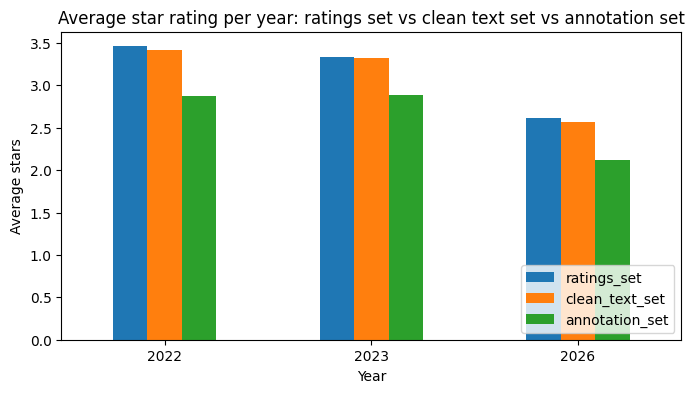

In [62]:
mean_rating_all.plot(kind='bar', figsize=(8, 4))
plt.title('Average star rating per year: ratings set vs clean text set vs annotation set')
plt.xlabel('Year')
plt.ylabel('Average stars')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [63]:
star_pct_all = pd.DataFrame({
    'ratings_set': df_ratings['score'].value_counts(normalize=True),
    'clean_text_set': df_clean_full['score'].value_counts(normalize=True),
    'annotation_set': df_annotate_unique['score'].value_counts(normalize=True)}).sort_index().mul(100).round(1)
star_pct_all

,ratings_set,clean_text_set,annotation_set
score,,,
1,31.6,32.2,42.1
2,6.8,7.0,9.4
3,7.1,7.1,9.0
4,9.8,9.8,9.6
5,44.7,43.8,29.9


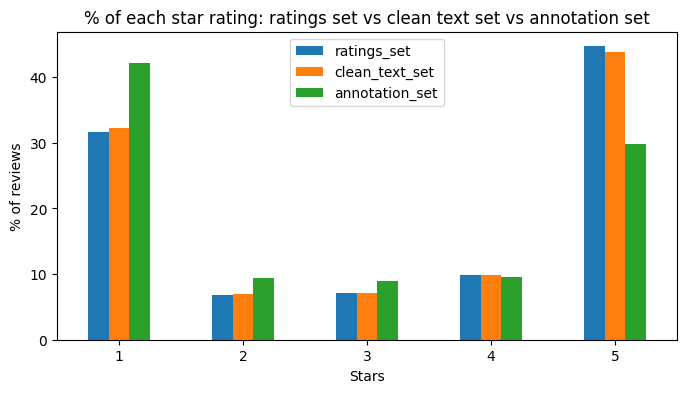

In [64]:
star_pct_all.plot(kind='bar', figsize=(8, 4))
plt.title('% of each star rating: ratings set vs clean text set vs annotation set')
plt.xlabel('Stars')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.show()

In [65]:
star_counts_all = pd.concat({
    'ratings_set': pd.crosstab(df_ratings['year'], df_ratings['score']).stack(),
    'clean_text_set': pd.crosstab(df_clean_full['year'], df_clean_full['score']).stack(),
    'annotation_set': pd.crosstab(df_annotate_unique['year'], df_annotate_unique['score']).stack()}, axis=1)
star_counts_all

ratings_set  clean_text_set  annotation_set
year score                                             
2022 1            23235           21580           19375
     2             4978            4706            4383
     3             5448            5028            4307
     4             8510            7822            5054
     5            40238           35803           15930
2023 1            19115           17646           16096
     2             4650            4312            4047
     3             4861            4460            4056
     4             6618            6087            4438
     5            28874           26078           13605
2026 1            11617           11114           10289
     2             2034            1967            1825
     3             1723            1642            1441
     4             1520            1431             987
     5             7140            6523            2982

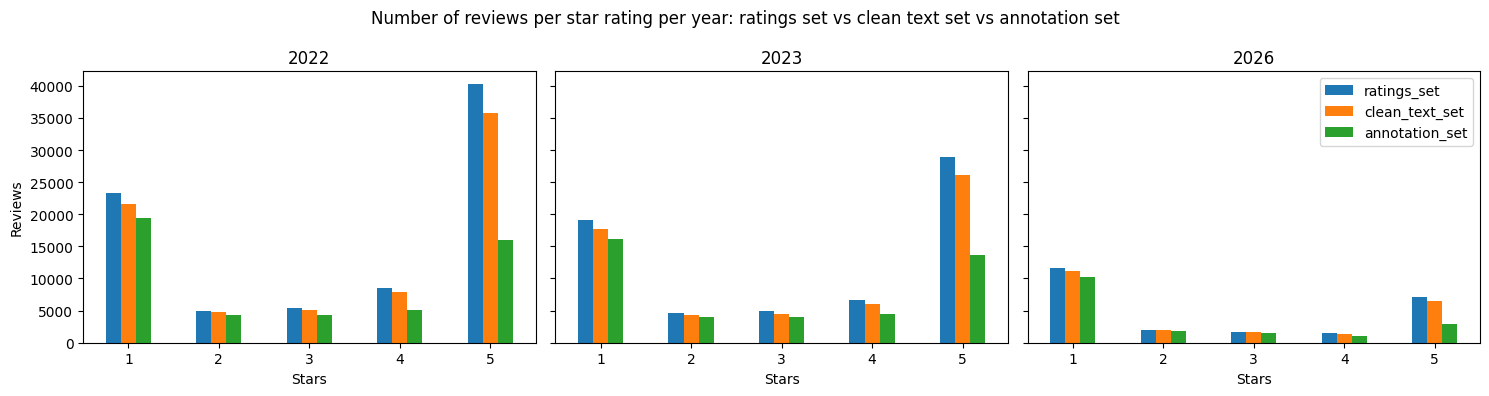

In [66]:
years = star_counts_all.index.get_level_values('year').unique()
fig, axes = plt.subplots(1, len(years), figsize=(15, 4), sharey=True)

for ax, year in zip(axes, years):
    star_counts_all.loc[year].plot(kind='bar', ax=ax, legend=False)
    ax.set_title(str(year))
    ax.set_xlabel('Stars')
    ax.tick_params(axis='x', rotation=0)

axes[0].set_ylabel('Reviews')
axes[-1].legend()
fig.suptitle('Number of reviews per star rating per year: ratings set vs clean text set vs annotation set')
plt.tight_layout()
plt.show()